In [2]:
%run 4-Train_RandomForestClassifier.ipynb

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

sns.set_theme(style="whitegrid")

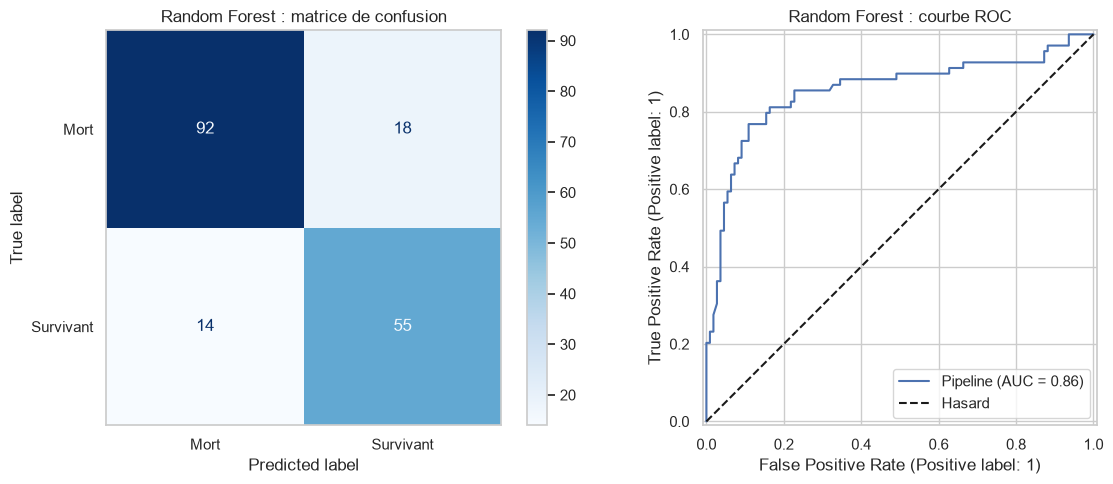

In [4]:
# Matrice de confusion (gauche) et courbe ROC (droite) sur la partie test
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Mort", "Survivant"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Random Forest : matrice de confusion")
axes[0].grid(False)

RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Hasard")
axes[1].set_title("Random Forest : courbe ROC")
axes[1].legend()

plt.tight_layout()
plt.show()

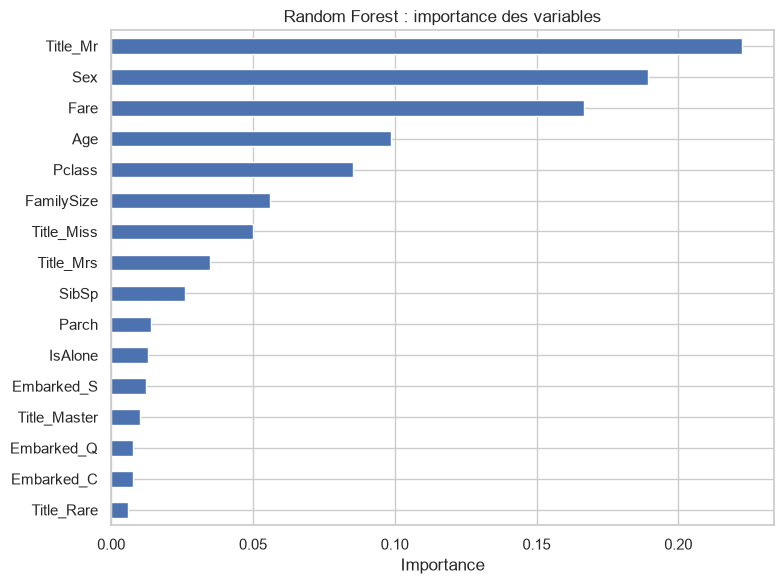

In [5]:
importances = pd.Series(
    model.named_steps["classifier"].feature_importances_,
    index=model.named_steps["preprocessing"].get_feature_names_out(),
).sort_values()

importances.plot.barh(figsize=(8, 6))
plt.title("Random Forest : importance des variables")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()